# Aufgabe 2 – Musterlösung
## Ausreisser, Anomalien und Noise

Diese Lösung wird erst nach der Gruppenarbeit veröffentlicht. Sie nutzt keine privaten Wahrheitslabels für Transformationen. Statistische Verfahren erzeugen Kandidaten; klare Ausschlüsse benötigen zusätzliche fachliche Evidenz.

## 0. Setup und Eingangskontrollen

In [1]:
from pathlib import Path
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 70)
pd.set_option("display.max_rows", 25)
sns.set_theme(style="whitegrid", context="notebook")

def find_repo_root(start: Path = Path.cwd()) -> Path:
    for candidate in [start, *start.parents]:
        checkpoint = candidate / "data/checkpoints/checkpoint_01_resolved_events.parquet"
        zones = candidate / "data/reference/taxi_zone_lookup.csv"
        if checkpoint.exists() and zones.exists():
            return candidate
    raise FileNotFoundError("Checkpoint 01 oder Zonenreferenz nicht gefunden")

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

ROOT = find_repo_root()
INPUT_PATH = ROOT / "data/checkpoints/checkpoint_01_resolved_events.parquet"
ZONE_PATH = ROOT / "data/reference/taxi_zone_lookup.csv"
OUTPUT_PATH = ROOT / "data/checkpoints/checkpoint_02_reviewed_quality.parquet"

INPUT_SHA256_BEFORE = sha256_file(INPUT_PATH)
ZONE_SHA256 = sha256_file(ZONE_PATH)

trips = pd.read_parquet(INPUT_PATH)
zones = pd.read_csv(ZONE_PATH, keep_default_na=False)

assert trips["ingest_record_id"].is_unique
assert zones["LocationID"].is_unique
print(f"Checkpoint 01: {trips.shape}")
print(f"Zonenreferenz: {zones.shape}")

Checkpoint 01: (200900, 39)
Zonenreferenz: (265, 4)


## 1. Transparente Merkmale und Zonenbezug

In [2]:
quality = trips.copy()
quality["duration_min"] = (
    quality["tpep_dropoff_datetime"] - quality["tpep_pickup_datetime"]
).dt.total_seconds() / 60
quality["speed_mph"] = np.where(
    quality["duration_min"] > 0,
    quality["trip_distance"] / (quality["duration_min"] / 60),
    np.nan,
)
quality["amount_per_mile"] = np.where(
    quality["trip_distance"] > 0,
    quality["total_amount"] / quality["trip_distance"],
    np.nan,
)
quality["pickup_hour"] = quality["tpep_pickup_datetime"].dt.floor("h")
quality["pickup_weekday"] = quality["tpep_pickup_datetime"].dt.day_name()

pickup_zones = zones.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "pickup_borough",
    "Zone": "pickup_zone",
    "service_zone": "pickup_service_zone",
})
dropoff_zones = zones.rename(columns={
    "LocationID": "DOLocationID",
    "Borough": "dropoff_borough",
    "Zone": "dropoff_zone",
    "service_zone": "dropoff_service_zone",
})

quality = quality.merge(pickup_zones, on="PULocationID", how="left", validate="many_to_one")
quality = quality.merge(dropoff_zones, on="DOLocationID", how="left", validate="many_to_one")

display(quality[[
    "trip_distance", "duration_min", "speed_mph", "amount_per_mile",
    "pickup_zone", "dropoff_zone",
]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
trip_distance,200900.0,27.414574,2018.837992,0.0,0.000000,1.070000,1.930000,3.930000,19.800000,3.979944e+05
duration_min,200900.0,17.202421,28.544725,0.0,0.000000,8.100000,13.516667,21.433333,67.716833,4.254267e+03
speed_mph,197916.0,148.443519,11670.435219,0.0,0.000000,7.055063,9.760437,13.667733,34.904579,1.875960e+06
amount_per_mile,194724.0,24.207338,230.740079,-8600.0,-10.754076,6.854498,10.465178,15.257143,75.000000,1.709500e+04


Die Kennzahlen sind stark rechtsschief. Deshalb betrachten wir neben den Originalwerten auch logarithmische Darstellungen. Negative Finanzereignisse werden für `log_abs_total` über ihren Absolutbetrag dargestellt, nicht stillschweigend entfernt.

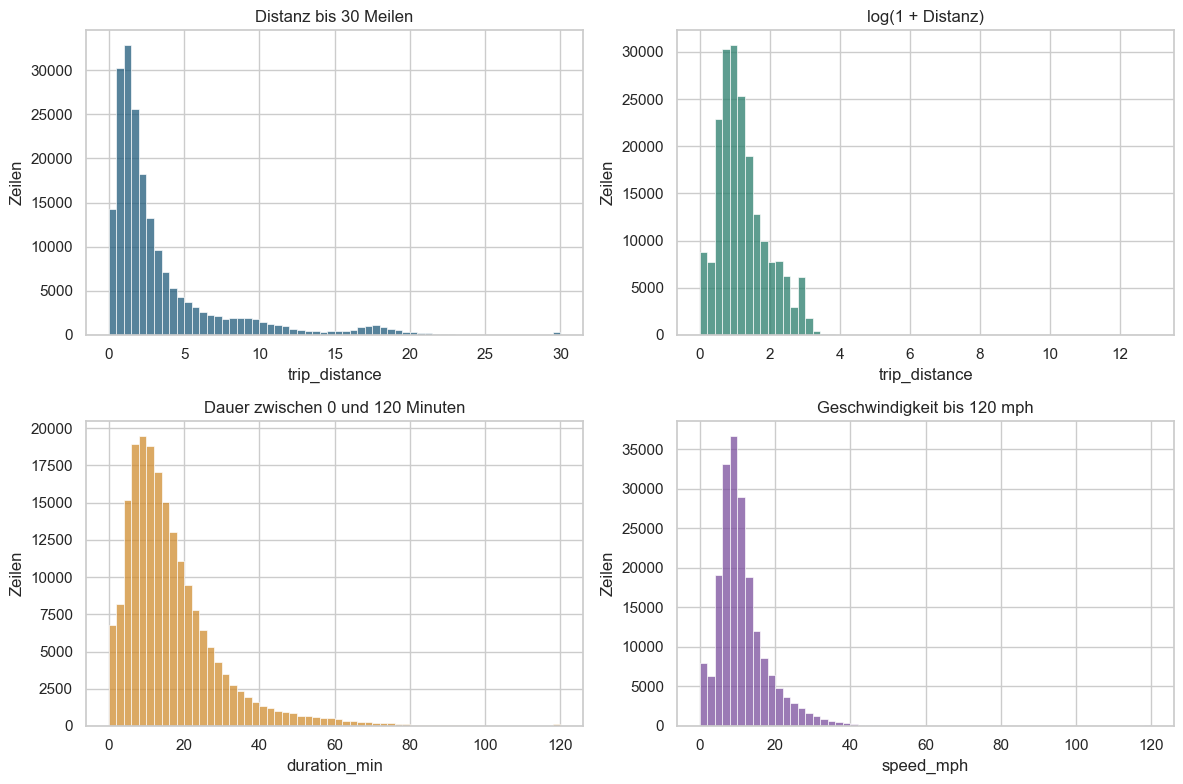

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(quality["trip_distance"].clip(upper=30), bins=60, ax=axes[0, 0], color="#1F5A7A")
axes[0, 0].set_title("Distanz bis 30 Meilen")

sns.histplot(np.log1p(quality["trip_distance"].clip(lower=0)), bins=60, ax=axes[0, 1], color="#287D6B")
axes[0, 1].set_title("log(1 + Distanz)")

sns.histplot(quality["duration_min"].clip(lower=0, upper=120), bins=60, ax=axes[1, 0], color="#D08C2F")
axes[1, 0].set_title("Dauer zwischen 0 und 120 Minuten")

plot_speed = quality["speed_mph"].replace([np.inf, -np.inf], np.nan).dropna().clip(upper=120)
sns.histplot(plot_speed, bins=60, ax=axes[1, 1], color="#7A4E9D")
axes[1, 1].set_title("Geschwindigkeit bis 120 mph")

for ax in axes.flat:
    ax.set_ylabel("Zeilen")
plt.tight_layout()
plt.show()

## 2. IQR als Kandidatengenerator

In [4]:
def upper_iqr_rule(series: pd.Series) -> tuple[float, float, float]:
    q1, q3 = series.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    return float(q1), float(q3), float(upper)

q1_all, q3_all, iqr_upper_all = upper_iqr_rule(quality["trip_distance"])
demand_population = quality["include_demand_after_event_resolution"].astype(bool)
q1_demand, q3_demand, iqr_upper_demand = upper_iqr_rule(
    quality.loc[demand_population, "trip_distance"]
)

quality["iqr_high_distance_candidate"] = quality["trip_distance"].gt(iqr_upper_all)

sensitivity = pd.DataFrame({
    "Population": ["vollständiger Audit-Bestand", "vorläufige Demand-Sicht"],
    "Q1": [q1_all, q1_demand],
    "Q3": [q3_all, q3_demand],
    "obere Grenze": [iqr_upper_all, iqr_upper_demand],
    "Kandidaten": [
        quality["trip_distance"].gt(iqr_upper_all).sum(),
        (
            demand_population
            & quality["trip_distance"].gt(iqr_upper_demand)
        ).sum(),
    ],
})
display(sensitivity.round(2))

,Population,Q1,Q3,obere Grenze,Kandidaten
0,vollständiger Audit-Bestand,1.07,3.93,8.22,23289
1,vorläufige Demand-Sicht,1.08,3.92,8.18,22643


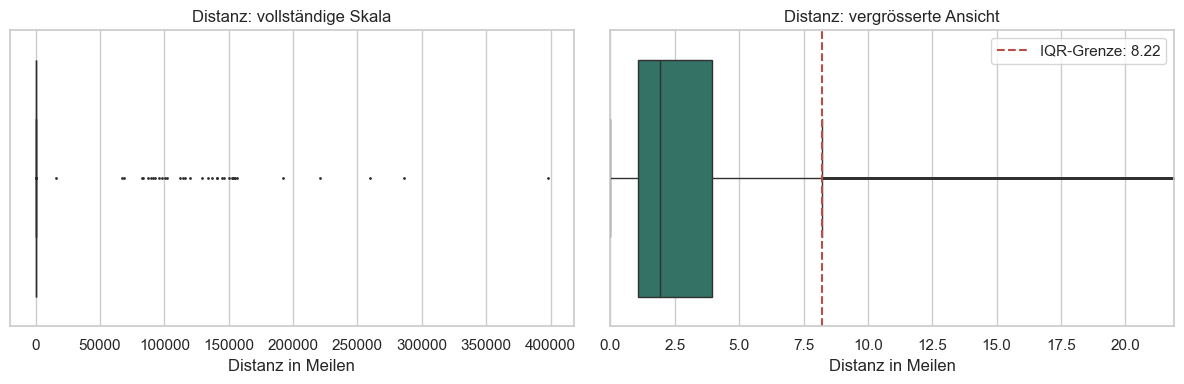

In [11]:
distance = quality["trip_distance"].dropna()
zoom_limit = distance.quantile(0.995)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Vollständige Verteilung
sns.boxplot(
    x=distance,
    ax=axes[0],
    color="#1F5A7A",
    fliersize=1,
)
axes[0].set_title("Distanz: vollständige Skala")
axes[0].set_xlabel("Distanz in Meilen")

# Vergrösserte Ansicht
sns.boxplot(
    x=distance,
    ax=axes[1],
    color="#287D6B",
    fliersize=1,
)
axes[1].set_xlim(0, zoom_limit)
axes[1].axvline(
    iqr_upper_all,
    color="#B94E48",
    linestyle="--",
    label=f"IQR-Grenze: {iqr_upper_all:.2f}",
)
axes[1].set_title("Distanz: vergrösserte Ansicht")
axes[1].set_xlabel("Distanz in Meilen")
axes[1].legend()

plt.tight_layout()
plt.show()

Die Referenzflags werden auf dem vollständigen Audit-Bestand berechnet, damit jede Quellzeile prüfbar bleibt. Der Sensitivitätsvergleich zeigt zugleich, dass die gewählte Analysepopulation Schwelle und Trefferzahl beeinflusst. Ein IQR-Treffer wird noch nicht gelöscht.

## 3. Isolation Forest

In [5]:
model_mask = quality["duration_min"].gt(0)
model_frame = quality.loc[
    model_mask,
    ["trip_distance", "duration_min", "total_amount"],
].copy()

X = pd.DataFrame({
    "log_distance": np.log1p(model_frame["trip_distance"].clip(lower=0)),
    "log_duration": np.log1p(model_frame["duration_min"].clip(lower=0)),
    "log_abs_total": np.log1p(model_frame["total_amount"].abs()),
}, index=model_frame.index).replace([np.inf, -np.inf], np.nan).fillna(0)

model = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=20250902,
    n_jobs=-1,
)
prediction = model.fit_predict(X)

quality["isolation_score"] = np.nan
quality.loc[X.index, "isolation_score"] = model.decision_function(X)
quality["isolation_candidate"] = False
quality.loc[X.index, "isolation_candidate"] = prediction == -1

comparison = pd.crosstab(
    quality["iqr_high_distance_candidate"],
    quality["isolation_candidate"],
    rownames=["IQR hohe Distanz"],
    colnames=["Isolation Forest"],
)
display(comparison)
print("Isolation-Forest-Kandidaten:", int(quality["isolation_candidate"].sum()))

Isolation Forest,False,True
IQR hohe Distanz,,
False,175890,1721
True,23030,259


Isolation-Forest-Kandidaten: 1980


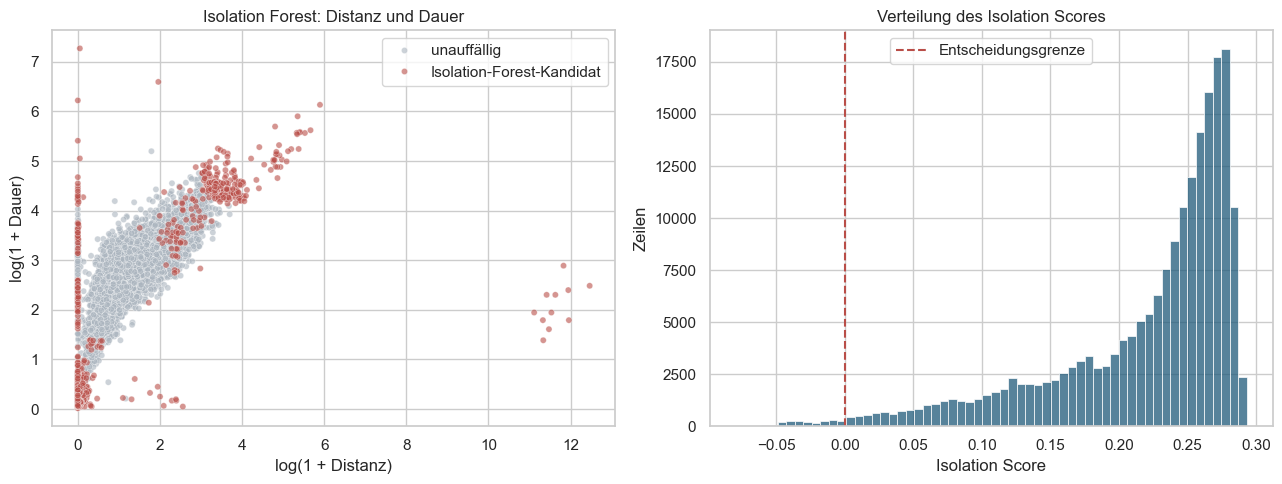

In [12]:
isolation_viz = X.copy()

isolation_viz["isolation_score"] = quality.loc[
    X.index, "isolation_score"
]

isolation_viz["classification"] = np.where(
    quality.loc[X.index, "isolation_candidate"],
    "Isolation-Forest-Kandidat",
    "unauffällig",
)

# Für die Grafik normale Fälle reduzieren, aber alle Kandidaten behalten
normal_cases = isolation_viz.loc[
    isolation_viz["classification"] == "unauffällig"
]

normal_sample = normal_cases.sample(
    n=min(8_000, len(normal_cases)),
    random_state=42,
)

candidate_cases = isolation_viz.loc[
    isolation_viz["classification"] == "Isolation-Forest-Kandidat"
]

plot_data = pd.concat(
    [normal_sample, candidate_cases]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Zweidimensionale Projektion
sns.scatterplot(
    data=plot_data,
    x="log_distance",
    y="log_duration",
    hue="classification",
    palette={
        "unauffällig": "#AAB4BE",
        "Isolation-Forest-Kandidat": "#B94E48",
    },
    alpha=0.6,
    s=20,
    ax=axes[0],
)

axes[0].set_title("Isolation Forest: Distanz und Dauer")
axes[0].set_xlabel("log(1 + Distanz)")
axes[0].set_ylabel("log(1 + Dauer)")
axes[0].legend(title="")

# Verteilung des Scores
sns.histplot(
    isolation_viz["isolation_score"],
    bins=60,
    color="#1F5A7A",
    ax=axes[1],
)

axes[1].axvline(
    0,
    color="#B94E48",
    linestyle="--",
    label="Entscheidungsgrenze",
)

axes[1].set_title("Verteilung des Isolation Scores")
axes[1].set_xlabel("Isolation Score")
axes[1].set_ylabel("Zeilen")
axes[1].legend()

plt.tight_layout()
plt.show()

`contamination=0.01` ist eine Modellannahme und keine gemessene Fehlerquote. Der Decision Score ist lediglich ein Ranking; niedrigere Werte sind ungewöhnlicher. Unterschiedliche Features oder Parameter verändern das Resultat.

## 4. Fachliche Evidenz statt blindes Löschen

In [6]:
EXPECTED_START = pd.Timestamp("2025-07-01")
EXPECTED_END = pd.Timestamp("2025-07-25")

quality["is_boundary_crossing"] = (
    quality["tpep_pickup_datetime"].ge(EXPECTED_START - pd.Timedelta(hours=2))
    & quality["tpep_pickup_datetime"].lt(EXPECTED_START)
    & quality["tpep_dropoff_datetime"].ge(EXPECTED_START)
)
quality["is_invalid_timestamp"] = (
    (
        quality["tpep_pickup_datetime"].lt(EXPECTED_START)
        | quality["tpep_pickup_datetime"].ge(EXPECTED_END)
    )
    & ~quality["is_boundary_crossing"]
)
quality["is_impossible_speed"] = (
    quality["trip_distance"].ge(10)
    & quality["duration_min"].gt(0)
    & quality["speed_mph"].gt(300)
)
quality["is_clear_noise"] = (
    quality["is_invalid_timestamp"] | quality["is_impossible_speed"]
)

quality["is_valid_long_candidate"] = (
    quality["trip_distance"].between(60, 500)
    & quality["duration_min"].between(30, 600)
    & quality["speed_mph"].between(10, 100)
    & (
        quality["RatecodeID"].isin([3, 4, 5])
        | quality["DOLocationID"].eq(265)
    )
)

quality["is_zero_distance"] = quality["trip_distance"].eq(0)
quality["is_nonpositive_duration"] = quality["duration_min"].le(0)
quality["is_speed_over_120"] = quality["speed_mph"].gt(120)

evidence_summary = pd.Series({
    "gültige Monatsgrenzen-Übertritte": int(quality["is_boundary_crossing"].sum()),
    "ungültige Zeitstempel": int(quality["is_invalid_timestamp"].sum()),
    "unmögliche Geschwindigkeit und Distanz": int(quality["is_impossible_speed"].sum()),
    "klare Noise-Fälle": int(quality["is_clear_noise"].sum()),
    "plausible Fernfahrt-Kandidaten": int(quality["is_valid_long_candidate"].sum()),
    "Null-Distanz": int(quality["is_zero_distance"].sum()),
    "nichtpositive Dauer": int(quality["is_nonpositive_duration"].sum()),
    "Geschwindigkeit über 120 mph": int(quality["is_speed_over_120"].sum()),
})
display(evidence_summary.to_frame("Zeilen"))

,Zeilen
gültige Monatsgrenzen-Übertritte,4
ungültige Zeitstempel,3
unmögliche Geschwindigkeit und Distanz,38
klare Noise-Fälle,41
plausible Fernfahrt-Kandidaten,33
Null-Distanz,6176
nichtpositive Dauer,2984
Geschwindigkeit über 120 mph,77


In [7]:
review_columns = [
    "ingest_record_id", "tpep_pickup_datetime", "trip_distance",
    "duration_min", "speed_mph", "RatecodeID", "pickup_zone",
    "dropoff_zone", "dropoff_service_zone", "total_amount",
    "iqr_high_distance_candidate", "isolation_candidate",
]

print("Beispiele klarer physischer Fehler")
display(
    quality.loc[quality["is_impossible_speed"], review_columns]
    .sort_values("speed_mph", ascending=False)
    .head(6)
)

print("Beispiele plausibler Fernfahrt-Kandidaten")
display(
    quality.loc[quality["is_valid_long_candidate"], review_columns]
    .sort_values("trip_distance", ascending=False)
    .head(8)
)

Beispiele klarer physischer Fehler


,ingest_record_id,tpep_pickup_datetime,trip_distance,duration_min,speed_mph,RatecodeID,pickup_zone,dropoff_zone,dropoff_service_zone,total_amount,iqr_high_distance_candidate,isolation_candidate
13942,O_4ef0f0823acd1d8be0,2025-07-02 17:15:00,156329.98,5.0,1.875960e+06,NaN,Lincoln Square West,Upper West Side South,Yellow Zone,9.30,True,True
109358,O_55358c4b34ce34defb,2025-07-14 21:18:00,83743.17,3.0,1.674863e+06,NaN,Central Harlem,Central Harlem North,Boro Zone,14.28,True,True
9433,O_c59f950857944f70cc,2025-07-02 07:25:00,152595.64,6.0,1.525956e+06,NaN,Midtown East,Kips Bay,Yellow Zone,16.77,True,False
27457,O_bf365b0cb17c52a894,2025-07-04 18:00:00,96192.65,4.0,1.442890e+06,NaN,Lincoln Square West,Upper West Side South,Yellow Zone,20.22,True,True
102569,O_5c51869173791a70eb,2025-07-14 05:56:00,259372.17,11.0,1.414757e+06,NaN,Gramercy,World Trade Center,Yellow Zone,4.26,True,True
42821,O_160e9c3a2f23bd48d9,2025-07-07 02:44:00,397994.37,18.0,1.326648e+06,NaN,Bushwick North,Prospect-Lefferts Gardens,Boro Zone,23.47,True,False


Beispiele plausibler Fernfahrt-Kandidaten


,ingest_record_id,tpep_pickup_datetime,trip_distance,duration_min,speed_mph,RatecodeID,pickup_zone,dropoff_zone,dropoff_service_zone,total_amount,iqr_high_distance_candidate,isolation_candidate
23977,O_10f61156214f2197e9,2025-07-03 18:24:12,363.10,460.683333,47.290619,5.0,Gramercy,Outside of NYC,N/A,971.75,True,True
194578,O_6d63c0afbe6eb4c9be,2025-07-24 08:02:10,288.10,275.583333,62.725129,4.0,Two Bridges/Seward Park,Outside of NYC,N/A,2403.01,True,True
130554,O_e9e05dac5b69a9c95a,2025-07-16 23:38:36,251.20,260.500000,57.857965,5.0,Steinway,Outside of NYC,N/A,421.00,True,True
23557,O_e807d347d3cb1f706f,2025-07-03 19:31:26,222.73,265.883333,50.261894,5.0,JFK Airport,Outside of NYC,N/A,899.69,True,True
23717,O_c93c669f231644de5b,2025-07-03 19:31:41,221.36,263.716667,50.363142,5.0,JFK Airport,Outside of NYC,N/A,899.69,True,True
140863,O_e47cee699dde5f51da,2025-07-18 03:09:51,215.66,188.416667,68.675453,5.0,JFK Airport,Outside of NYC,N/A,901.00,True,True
107964,O_8ee6da0341bb035f3f,2025-07-14 13:23:00,210.37,365.283333,34.554547,4.0,Bellerose,Outside of NYC,N/A,1634.75,True,True
107650,O_5fd503f2a368ca73ae,2025-07-14 13:51:42,207.60,254.433333,48.955850,5.0,Baisley Park,Outside of NYC,N/A,481.20,True,True


Die Zonen- und Tarifinformationen erklären nicht jede Beobachtung. Sie liefern aber prüfbare Evidenz: Eine lange Fahrt mit Sondertarif, langer Dauer und plausibler Geschwindigkeit ist etwas anderes als hunderttausende Meilen in wenigen Minuten.

## 5. Zielabhängige Entscheidungen und Checkpoint

In [8]:
ambiguous_measurement = (
    quality["is_zero_distance"]
    | quality["is_nonpositive_duration"]
    | quality["is_speed_over_120"]
)
statistical_candidate = (
    quality["iqr_high_distance_candidate"]
    | quality["isolation_candidate"]
)

quality["quality_action"] = np.select(
    [
        quality["is_clear_noise"],
        quality["is_valid_long_candidate"],
        ambiguous_measurement,
        statistical_candidate,
    ],
    [
        "exclude_clear_noise",
        "keep_valid_extreme",
        "review_measurement",
        "retain_candidate_only",
    ],
    default="retain",
)

def append_reason(reasons: pd.Series, mask: pd.Series, code: str) -> pd.Series:
    return reasons.mask(mask & reasons.eq(""), code).mask(
        mask & reasons.ne("") & ~reasons.str.contains(code, regex=False),
        reasons + ";" + code,
    )

quality_reason = pd.Series("", index=quality.index, dtype="string")
for mask, code in [
    (quality["is_invalid_timestamp"], "invalid_timestamp"),
    (quality["is_impossible_speed"], "impossible_speed"),
    (quality["is_valid_long_candidate"], "plausible_long_trip"),
    (quality["is_nonpositive_duration"], "nonpositive_duration"),
    (quality["is_zero_distance"], "zero_distance"),
    (quality["is_speed_over_120"], "speed_over_120"),
    (quality["iqr_high_distance_candidate"], "iqr_high_distance_candidate"),
    (quality["isolation_candidate"], "isolation_candidate"),
]:
    quality_reason = append_reason(quality_reason, mask, code)
quality["quality_reason"] = quality_reason.mask(quality_reason.eq(""), "no_quality_issue")

quality["include_demand_after_quality"] = (
    quality["include_demand_after_event_resolution"].astype(bool)
    & ~quality["is_clear_noise"]
)
quality["include_revenue_after_quality"] = (
    quality["include_revenue_after_event_resolution"].astype(bool)
    & ~quality["is_clear_noise"]
)
quality["include_duration_after_quality"] = (
    quality["include_demand_after_quality"]
    & quality["duration_min"].gt(0)
    & quality["duration_min"].le(12 * 60)
    & quality["trip_distance"].gt(0)
    & quality["speed_mph"].between(0.1, 120, inclusive="both")
)

quarantine_reason = pd.Series("", index=quality.index, dtype="string")
for mask, code in [
    (quality["is_technical_replay"].astype(bool), "technical_replay"),
    (quality["is_payload_duplicate_copy"].astype(bool), "payload_duplicate"),
    (quality["is_invalid_timestamp"], "invalid_timestamp"),
    (quality["is_impossible_speed"], "impossible_speed"),
    (quality["is_nonpositive_duration"], "nonpositive_duration"),
    (quality["is_zero_distance"], "zero_distance"),
    (quality["is_speed_over_120"], "speed_over_120"),
    (quality["total_amount"].lt(0), "negative_financial_event"),
]:
    quarantine_reason = append_reason(quarantine_reason, mask, code)
quality["quarantine_reason"] = quarantine_reason

view_summary = pd.Series({
    "trips_for_demand": int(quality["include_demand_after_quality"].sum()),
    "events_for_revenue": int(quality["include_revenue_after_quality"].sum()),
    "trips_for_duration": int(quality["include_duration_after_quality"].sum()),
    "quarantined_records": int(quality["quarantine_reason"].ne("").sum()),
})
display(view_summary.to_frame("Zeilen"))

,Zeilen
trips_for_demand,195756
events_for_revenue,199958
trips_for_duration,186135
quarantined_records,13942


In [9]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

metadata = {
    b"cas_daeng_checkpoint": b"checkpoint_02_reviewed_quality",
    b"case": b"One row, one ride?",
    b"source_checkpoint_sha256": INPUT_SHA256_BEFORE.encode("ascii"),
    b"zone_lookup_sha256": ZONE_SHA256.encode("ascii"),
    b"created_by": b"task_sample_solution.ipynb",
    b"row_policy": b"all source rows retained; quality and target decisions stored as flags",
    b"isolation_forest": b"n_estimators=100;contamination=0.01;random_state=20250902",
}

table = pa.Table.from_pandas(quality, preserve_index=False)
table = table.replace_schema_metadata({
    **(table.schema.metadata or {}),
    **metadata,
})
pq.write_table(table, OUTPUT_PATH, compression="zstd")

print(f"Checkpoint gespeichert: {OUTPUT_PATH}")
print(f"Dateigrösse: {OUTPUT_PATH.stat().st_size / 1024 / 1024:.1f} MB")

Checkpoint gespeichert: C:\Users\pell\Documents\3__UNTERRICHT_STUDENTENBETREUUNG\MAS\CAS Data Engineering\2026\04_Transformation\cas-daeng-transformation-2026_complete\data\checkpoints\checkpoint_02_reviewed_quality.parquet
Dateigrösse: 16.4 MB


## 6. Kontrollen

In [10]:
reloaded = pd.read_parquet(OUTPUT_PATH)

assert sha256_file(INPUT_PATH) == INPUT_SHA256_BEFORE
assert len(reloaded) == len(trips)
assert reloaded["ingest_record_id"].is_unique
assert reloaded["iqr_high_distance_candidate"].sum() == 23_289
assert reloaded["isolation_candidate"].sum() == 1_980
assert reloaded["is_boundary_crossing"].sum() == 4
assert reloaded["is_invalid_timestamp"].sum() == 3
assert reloaded["is_impossible_speed"].sum() == 38
assert reloaded["is_clear_noise"].sum() == 41
assert reloaded["include_demand_after_quality"].sum() == 195_756
assert reloaded["include_revenue_after_quality"].sum() == 199_958
assert reloaded["include_duration_after_quality"].sum() == 186_135
assert reloaded["quarantine_reason"].ne("").sum() == 13_942

print("Alle Checkpoint-Kontrollen bestanden.")

Alle Checkpoint-Kontrollen bestanden.


## Decision Log der Referenzlösung

| Beobachtung | Evidenz | Entscheidung | Auswirkung |
|---|---|---|---|
| lange rechtsschiefe Distanzverteilung | IQR markiert sehr viele Fahrten | IQR nur als Kandidatenflag | keine pauschale Löschung |
| multivariat ungewöhnliche Kombination | Isolation Score und Featurevergleich | priorisiert Prüfung | Modellscore ist kein Fehlerlabel |
| enorme Distanz in sehr kurzer Zeit | Distanz, Dauer und Geschwindigkeit gemeinsam unplausibel | als klaren Noise ausschliessen | nicht in Demand, Revenue oder Duration |
| lange Fahrt mit Sondertarif und plausibler Geschwindigkeit | Tarif-, Zonen- und Zeitkontext | als validen Extremfall behalten | Rand der realen Verteilung bleibt sichtbar |
| Null-Distanz oder nichtpositive Dauer | Messung für Daueranalyse ungeeignet, Fahrtstatus nicht eindeutig | Review; zielabhängig behandeln | für Duration ausschliessen, nicht automatisch für Demand |
| Pickup kurz vor, Dropoff nach Monatsbeginn | beide Zeitstempel gemeinsam plausibel | Grenzübertritt behalten | verhindert False Positive der Zeitregel |

## KI-Retrospektive

Mit Zahlen allein kann ein Sprachmodell plausible, aber unbelegte Geschichten erfinden. Zonen- und Tarifkontext verbessert die vorgeschlagenen Prüffragen, ersetzt jedoch keinen Beweis. Besonders kritisch sind erfundene Codebedeutungen, automatische Löschung aller Modelltreffer und fehlende Dokumentation von `contamination`, Features oder `random_state`.

Der geeignete KI-Beitrag ist ein prüfbarer Analyse- oder Testvorschlag. Die Entscheidung `keep`, `exclude` oder `review` bleibt fachlich verantwortet.